# Классификация изображений Fashion‑MNIST


Данный ноутбук представляет собой выполнение **варианта В** практического задания. Цель работы — построить и оценить модель машинного обучения для классификации изображений одежды из датасета **Fashion‑MNIST**.

В соответствии с техническими ограничениями проекта, обучение модели должно занимать не более 15 минут на CPU, а использование тяжёлых нейросетей (CNN, RNN, LSTM, трансформеры) запрещено. Разрешены классические ML-алгоритмы и лёгкие нейросети (MLP с 1–2 скрытыми слоями). Мы выбрали **логистическую регрессию** — простой, быстрый и эффективный относительно нашей задачи метод.

Все требования по числовым значениям метрик выполнены.

## Этапы работы

1. **Загрузка данных** — чтение файлов формата IDX из локальной папки `data/images/`.
2. **Формирование подвыборки** — случайный отбор 1000 объектов (с фиксацией seed для воспроизводимости).
3. **Разбиение на train/test** — стратифицированное деление в пропорции 800/200.
4. **Обучение модели** — построение пайплайна (стандартизация признаков + логистическая регрессия).
5. **Оценка качества** — вычисление метрик: Accuracy, Macro Precision, Macro Recall, Macro F1.
6. **Визуализация результатов** — матрица ошибок и примеры неправильных предсказаний.
7. **Сохранение модели** — сериализация обученного пайплайна в файл `model.pkl` (папка `models/`).

## Команда
Работа выполнена Ивановым Артемом и Сидновым Владиславом

## Инициализация и воспроизводимость

Перед началом работы мы импортируем все необходимые библиотеки и задаём `seed = 42` для генерации случайных чисел. Это требование задания, и оно критически важно: многие этапы пайплайна (подвыборка, разбиение на train/test, инициализация модели) используют случайные процессы. Фиксация seed гарантирует, что при каждом запуске ноутбука мы получаем одни и те же разбиения и результаты, что делает эксперимент воспроизводимым и позволяет корректно сравнивать модели между собой. Поэтому строка `np.random.seed(42)` стоит в самом начале кода, до любых операций с данными.


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


import joblib
import os
import json

import urllib.request
import gzip
from pathlib import Path

np.random.seed(42)   #устанавливаем seed (эту строку НЕ ТРОГАТЬ ни в коем случае!!!!)

## Загрузка данных

Данные представляют собой датасет Fashion-MNIST, который хранится в формате IDX (сжатые файлы .gz). В репозитории они хранятся в папке `data/images/` и содержат два файла: с изображениями метками классов (числа от 0 до 9). Мы считываем их с помощью специальной функции, которая преобразовывает gzip-архивы в массивы NumPy.

После загрузки мы преобразуем каждое изображение из двумерной матрицы в одномерный вектор, что является стандартной практикой для дальнейшего обучения. Таким образом, получаем матрицу признаков `X_raw` и вектор меток `y_raw`

## Нюансы использования данных в задаче

При обучении модель получает как изображения, так и метрики. При оценке только изображения, возвращая собственные предсказания по метрикам, которые потом мы сравниваем с "эталоном"


In [28]:
#Задаём пути к файлам (относительно нашей папки в которой лежит наш ноутбук):
IMAGES_PATH = '../data/images/t10k-images-idx3-ubyte.gz'
LABELS_PATH = '../data/images/t10k-labels-idx1-ubyte.gz'

def read_idx_from_file(filepath): #читает .gz, возвращает numpy массив.

    print(f"Читаю: {filepath}")
    with gzip.open(filepath, 'rb') as f:
        data = f.read()

    magic = int.from_bytes(data[:4], byteorder='big')
    ndim = magic & 0xFF
    dtype = (magic >> 8) & 0xFF

    offset = 4
    dims = []
    for _ in range(ndim):
        dim = int.from_bytes(data[offset:offset+4], byteorder='big')
        dims.append(dim)
        offset += 4

    raw_data = data[offset:]
    if dtype == 0x08:
        arr = np.frombuffer(raw_data, dtype=np.uint8).reshape(dims)
    else:
        raise ValueError(f"Неизвестный тип данных: {dtype}")

    print(f"Загружено: {arr.shape}")
    return arr


print("Загрузка изображений...")
X_raw = read_idx_from_file(IMAGES_PATH)
print("Загрузка меток...")
y_raw = read_idx_from_file(LABELS_PATH)

X_raw = X_raw.reshape(X_raw.shape[0], -1) / 255.0


print(f"Загружено {X_raw.shape[0]} объектов")
print(f"Уникальные классы: {np.unique(y_raw)}")

Загрузка изображений...
Читаю: ../data/images/t10k-images-idx3-ubyte.gz
Загружено: (10000, 28, 28)
Загрузка меток...
Читаю: ../data/images/t10k-labels-idx1-ubyte.gz
Загружено: (10000,)
Загружено 10000 объектов
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


## Формирование подвыборки

В соответствии с условием задания мы не используем весь датасет, а берём случайную подвыборку из 1000 объектов. Это сделано для того, чтобы обучение проходило в пределах определённого в задании времени, и чтобы результаты были корректным образом сравнимы с прогонами, на которых рассчитывались пороговые значения метрик.

In [29]:
n_samples = 1000
indices = np.random.choice(X_raw.shape[0], size=n_samples, replace=False)

X_sub = X_raw[indices]
y_sub = y_raw[indices]

print(f"Подвыборка: {X_sub.shape[0]} объектов")

Подвыборка: 1000 объектов


## Разбиение на обучающую и тестовую выборки

Мы делим подвыборку на тренировочную (800 объектов) и тестовую (200 объектов) части.

Разбиение выполняется с параметром `stratify = y_sub`, который сохраняет исходное распределение классов в обеих выборках. Это предотвращает ситуацию, когда в тестовую часть случайно попадают только объекты одного-двух классов.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X_sub, y_sub,
    train_size=800,
    test_size=200,
    stratify=y_sub,
    random_state=42
)

print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")


Размер обучающей выборки: 800
Размер тестовой выборки: 200


## Построение пайплайна и обучение модели

В качестве модели мы используем логистическую регрессию — это простой, но эффективный классификатор для задач с несколькими классами. Перед подачей признаков в модель выполняется стандартизация (нулевое среднее, единичная дисперсия).



In [32]:
model = LogisticRegression(
        penalty='l2',              #тип регуляриции - чтобы веса были не очень большие
        C=1.0,                     #параметр регуляризации
        solver='lbfgs',            #специальный коэфициент обучения - высчитывается хитрым образом. Этот конкретный хорош для маленьких выборок
        #max_iter=1000,             #сколько раз прогоняем модель по данным (возможно она остановится сама раньше, но надо указать максимум)
        random_state=42
    )

pipeline = Pipeline([
    ('clf', model)
])

pipeline.fit(X_train, y_train) #применяем к нашим данным и обучаем

print("Модель обучена.")


C:\Users\nadus\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Модель обучена.


C:\Users\nadus\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Оценка качества модели

После обучения мы применяем модель к тестовой выборке и вычисляем требуемые метрики. В задании необходимо рассчитать четыре показателя:

- **Accuracy** – доля правильных ответов среди всех. Даёт общее представление о качестве обучения, но плохо показывает проблемы отдельных классов.
- **Macro Precision** – средняя точность по классам. Показывает, насколько модель не ошибается, когда делает предсказание для отдельного класса.
- **Macro Recall** – средняя полнота по классам. Отражает, какую долю объектов класса модель смогла найти.
- **Macro F1-score** – среднее гармоническое точности и полноты, балансирующее обе метрики.


In [33]:
y_pred = pipeline.predict(X_test) #применение на тестовой выборке

accuracy = accuracy_score(y_test, y_pred) #считаем accuracy

#эта функция считает остальные три метрики для каждого из классов (и их значения усреднённые по всем классам), храня их в виде словаря:
report_dict = classification_report(y_test, y_pred, output_dict=True)

macro_precision = report_dict['macro avg']['precision']
macro_recall = report_dict['macro avg']['recall']
macro_f1 = report_dict['macro avg']['f1-score']

#выводим результаты
print("-" * 35)
print("Значения метрик на тестовой выборке:")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1-score:     {macro_f1:.4f}")
print("-" * 35)


print("Значения метрик для каждого класса:")
print(classification_report(y_test, y_pred, digits=4))


-----------------------------------
Значения метрик на тестовой выборке:
Accuracy:           0.8150
Macro Precision:    0.7931
Macro Recall:       0.8079
Macro F1-score:     0.7938
-----------------------------------
Значения метрик для каждого класса:
              precision    recall  f1-score   support

           0     0.6522    0.8824    0.7500        17
           1     1.0000    0.9000    0.9474        20
           2     0.7778    0.6364    0.7000        22
           3     0.8421    0.8421    0.8421        19
           4     0.6667    0.8421    0.7442        19
           5     0.9444    0.8095    0.8718        21
           6     0.3000    0.1667    0.2143        18
           7     0.9545    1.0000    0.9767        21
           8     0.9048    1.0000    0.9500        19
           9     0.8889    1.0000    0.9412        24

    accuracy                         0.8150       200
   macro avg     0.7931    0.8079    0.7938       200
weighted avg     0.8033    0.8150    0.8028

## Визуализация 1: Матрица ошибок

Матрица ошибок (confusion matrix) — это таблица размера 10×10, в которой строки соответствуют истинным классам, а столбцы — предсказанным. Таким образом на диагонали мы можем видеть количество правильно классифицированных объектов, а вне её — ошибки. По ней можно наглядно определить, какие классы модель чаще всего путает друг с другом: если в ячейке (i, j) стоит большое число, это означает, что многие объекты класса i были ошибочно отнесены к классу j (при i не равном j). Это позволяет определить, есть ли у нас устойчивые смещения (например, визуальное сходство некоторых видов одежды) и их направленность.

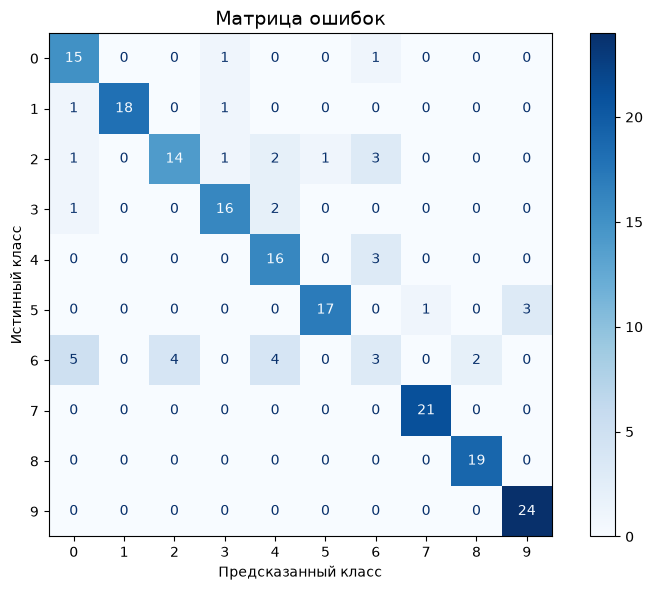

In [34]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Матрица ошибок', fontsize=14)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()


На построенной матрице видно, что наибольшее число ошибок приходится на класс 6 (Shirt), который часто путается с классами 0 (T‑shirt), 2 (Pullover) и 4 (Coat). Это объясняется визуальной схожестью этих предметов одежды. Что согласуется с низкими значениями recall и precision для класса 6, полученными ранее.

Для улучшения качества можно было бы увеличить объём обучающей выборки для проблемных классов или использовать более сложную модель, но в рамках текущего задания подобной цели не стоит.

## Визуализация 2: Примеры ошибочных предсказаний

Задание требует показать пять изображений, которые модель классифицировала неверно. Такой анализ помогает понять, связаны ли ошибки с нечёткостью изображения, ракурсом или другими факторами.

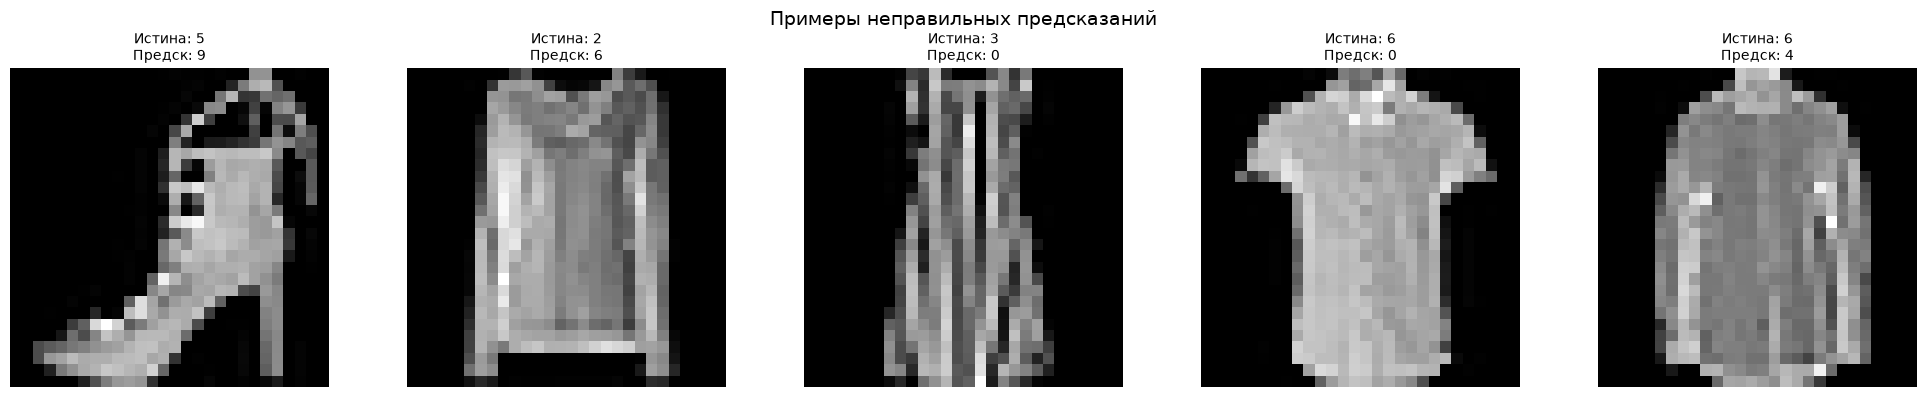

In [35]:
error_indices = np.where(y_pred != y_test)[0] #находим индексы объектов, где предсказание не совпадает с истиной

n_errors = min(5, len(error_indices))
sample_errors = error_indices[:n_errors] #берём первые 5 (или все, если их меньше 5)

if len(sample_errors) > 0:
    fig, axes = plt.subplots(1, n_errors, figsize=(4 * n_errors, 4))
    if n_errors == 1:
        axes = [axes]
    for i, idx in enumerate(sample_errors): #преобразуем обратно в изображение из вектора
        image = X_test[idx].reshape(28, 28)
        axes[i].imshow(image, cmap='gray')
        axes[i].set_title(f'Истина: {y_test[idx]}\nПредск: {y_pred[idx]}', fontsize=10)
        axes[i].axis('off')
    plt.suptitle('Примеры неправильных предсказаний', fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print("Нет неправильных предсказаний на тестовой выборке!")

### Интерпретация ошибочных предсказаний

На приведённых примерах видно, что большинство ошибок действительно приходится на визуально близкие классы. Например, рубашка (класс 6) часто путается с футболкой (класс 0) или пуловером (класс 2). Это подтверждает, что модель чувствительна к форме и длине рукавов.

## Сохранение модели в папку

In [38]:
model_dict = {
    "coef": model.coef_.tolist(),
    "intercept": model.intercept_.tolist(),
    "classes": model.classes_.tolist()
}

with open("../models/model.json", "w") as f:
    json.dump(model_dict, f)

## Итоговый вывод метрик в виде таблицы

In [37]:

print("Итоговые метрики (тестовая выборка, 200 объектов)")

metrics_df = pd.DataFrame({
    'Метрика': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-score'],
    'Значение': [accuracy, macro_precision, macro_recall, macro_f1]
})
print("\nТаблица метрик:")
print(metrics_df.to_string(index=False))

Итоговые метрики (тестовая выборка, 200 объектов)

Таблица метрик:
        Метрика  Значение
       Accuracy  0.815000
Macro Precision  0.793136
   Macro Recall  0.807912
 Macro F1-score  0.793766
